# Week 10A — Learning by Watching: Imitation Learning, Behavior Cloning, and DAgger

**CSCI 4932/5933 — Reinforcement Learning**  
**Learning goals:** (1) collect expert demonstrations, (2) train a policy by classification, (3) measure policy performance in closed-loop rollouts, (4) explain covariate shift, and (5) implement a compact DAgger loop.

**Big question:** *Can we teach an RL agent to act well without using policy-gradient optimization?*  
This notebook uses a hand-written **expert** in CartPole-v1, so students do **not** need to rerun PPO. The learner is trained with `CrossEntropyLoss`, not a policy-gradient loss.

### Software
- `numpy`, `torch`, `matplotlib`
- `gymnasium` recommended: `pip install gymnasium` (or `pip install 'gymnasium[classic-control]'` if you want rendering)

When Gymnasium is unavailable, the notebook can use a **minimal educational CartPole dynamics implementation** to execute the examples. Results in this fallback should not be interpreted as validation against the official Gymnasium environment.

**Integrity note:** The scripted controller is an *expert for this simple task*, not an optimality certificate. DAgger requires simulator rollouts and access to expert labels; unlike Week 10B, it is **not purely offline learning**.

## Part 1 — Warm-up: imitation is supervised learning

Suppose a thermostat expert chooses `1` (heat on) when current temperature is too far below target temperature. A network can imitate those labels. Notice there is no reward and no Bellman target.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

np.random.seed(11)
torch.manual_seed(11)
torch.set_num_threads(1)  # small networks run faster on many classroom CPUs
rng = np.random.default_rng(42)
current = rng.uniform(15, 25, 800)
target = rng.uniform(20, 24, 800)
features = torch.tensor(np.column_stack((current, target)), dtype=torch.float32)
labels = torch.tensor((current < target - 0.5).astype(np.int64))

thermostat = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2))
optimizer = torch.optim.Adam(thermostat.parameters(), lr=1e-2)

for epoch in range(150):
    logits = thermostat(features)
    loss = nn.functional.cross_entropy(logits, labels)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    
with torch.inference_mode():
    accuracy = (thermostat(features).argmax(dim=1) == labels).float().mean().item()
    decision = thermostat(torch.tensor([[18., 22.]])).argmax(dim=1).item()
print(f'Thermostat training accuracy: {accuracy:.1%}')
print('For 18°C current / 22°C target:', 'Heat ON' if decision else 'Heat OFF')

Thermostat training accuracy: 99.4%
For 18°C current / 22°C target: Heat ON


**Ask:** What labels trained the thermostat? Where did the labels come from? Would the thermostat necessarily minimize total electricity cost over a month? No: it was trained to imitate individual decisions, not optimize a long-term reward.

## Part 2 — The environment and expert

CartPole observation = `[cart position, cart velocity, pole angle, pole angular velocity]`. Actions = `0` (push left) or `1` (push right).

The teacher below is deliberately simple:

$$
a_E=\mathbf{1}(\theta+0.2\dot{\theta}>0)
$$

It reacts to how far the pole leans and how quickly it rotates. It is **not a learned RL agent**. A previously trained PPO policy could instead provide demonstrations using exactly the same data-collection function.

In [2]:
# Use the official Gymnasium environment when it is installed.
try:
    import gymnasium as gym
    HAS_GYMNASIUM = True
except ImportError:
    HAS_GYMNASIUM = False

class CartPoleLite:
    """Minimal educational CartPole physics fallback; not the official Gymnasium env."""
    def __init__(self):
        self.rng = np.random.default_rng(0)
        self.state = None
        self.steps = 0

    def reset(self, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        bounds = options or {}
        self.state = self.rng.uniform(bounds.get('low', -0.05),
                                      bounds.get('high', 0.05), 4)
        self.steps = 0
        return self.state.astype(np.float32).copy(), {}

    def step(self, action):
        x, x_dot, theta, theta_dot = self.state
        force = 10.0 if int(action) == 1 else -10.0
        c, s = np.cos(theta), np.sin(theta)
        temp = (force + 0.05 * theta_dot**2 * s) / 1.1
        theta_acc = (9.8 * s - c * temp) / (0.5 * (4./3. - 0.1*c*c/1.1))
        x_acc = temp - 0.05*theta_acc*c/1.1
        self.state = np.array([x + 0.02*x_dot,
                               x_dot + 0.02*x_acc,
                               theta + 0.02*theta_dot,
                               theta_dot + 0.02*theta_acc])
        self.steps += 1
        terminated = bool(abs(self.state[0]) > 2.4 or abs(self.state[2]) > np.deg2rad(12))
        truncated = self.steps >= 500
        return self.state.astype(np.float32).copy(), 1.0, terminated, truncated, {}

    def close(self):
        pass

def make_env():
    return gym.make('CartPole-v1') if HAS_GYMNASIUM else CartPoleLite()

def expert_action(obs):
    return int(float(obs[2]) + 0.2 * float(obs[3]) > 0)

print('Environment:', 'Gymnasium CartPole-v1' if HAS_GYMNASIUM else 'CartPoleLite educational fallback')
obs, _ = make_env().reset(seed=42)
print('An example observation:', obs, '\nExpert action:', expert_action(obs))

Environment: CartPoleLite educational fallback
An example observation: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ] 
Expert action: 1


## Part 3 — Gather expert demonstrations

Collect `(state, expert_action)` pairs from a few **complete expert episodes**. Also keep separate expert episodes for an honest held-out action-accuracy check. In sequential data, don't split randomly across adjacent timesteps if you can split whole trajectories.

Training demonstrations: (1000, 4) (1000,)
Held-out expert demonstrations: (2000, 4) (2000,)
Fraction of expert right-push actions: 0.5


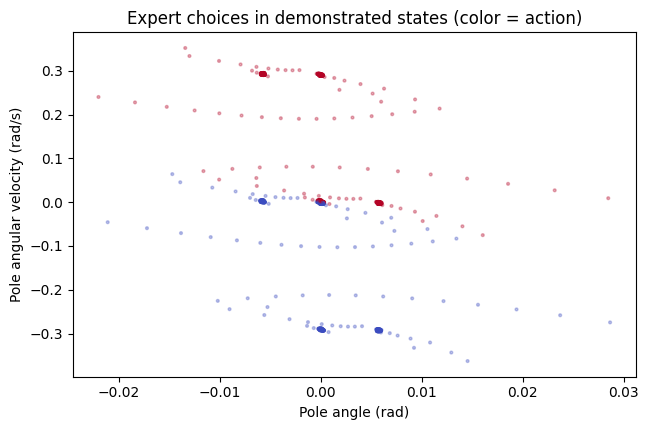

In [3]:
def collect_expert_episodes(n_episodes=2, seed_start=100):
    env = make_env()
    episode_states, episode_actions = [], []
    for episode in range(n_episodes):
        obs, _ = env.reset(seed=seed_start + episode)
        states, actions = [], []
        while True:
            a = expert_action(obs)
            states.append(obs.copy())
            actions.append(a)
            obs, reward, terminated, truncated, _ = env.step(a)
            if terminated or truncated:
                break
        episode_states.append(np.asarray(states, dtype=np.float32))
        episode_actions.append(np.asarray(actions, dtype=np.int64))
    env.close()
    return episode_states, episode_actions

train_episodes_s, train_episodes_a = collect_expert_episodes(2, seed_start=100)
test_episodes_s, test_episodes_a = collect_expert_episodes(4, seed_start=800)
X_train = np.concatenate(train_episodes_s)
y_train = np.concatenate(train_episodes_a)
X_test = np.concatenate(test_episodes_s)
y_test = np.concatenate(test_episodes_a)
print('Training demonstrations:', X_train.shape, y_train.shape)
print('Held-out expert demonstrations:', X_test.shape, y_test.shape)
print('Fraction of expert right-push actions:', y_train.mean().round(3))

plt.figure(figsize=(6.6, 4.4))
plt.scatter(X_train[:, 2], X_train[:, 3], c=y_train, s=4, alpha=.32, cmap='coolwarm')
plt.xlabel('Pole angle (rad)'); plt.ylabel('Pole angular velocity (rad/s)')
plt.title('Expert choices in demonstrated states (color = action)')
plt.tight_layout(); plt.show()

### Discussion checkpoint

1. What is the observation? What is the target label?
2. Why is the test split by **episode** instead of randomly shuffling neighboring timesteps?
3. What kinds of bad states will be missing when the expert consistently balances the pole?

## Part 4 — Behavior Cloning: train a policy network

This is the same `state → policy logits → action` architecture students saw for PPO, but its loss is now simple cross-entropy:

$$
L_{BC}=-\frac{1}{N}\sum_i\log\pi_{\theta}(a_i^E\mid s_i).
$$

Unlike PPO, **no rewards, returns, values, or advantages appear in this training loop.**

Held-out expert action accuracy: 80.5%


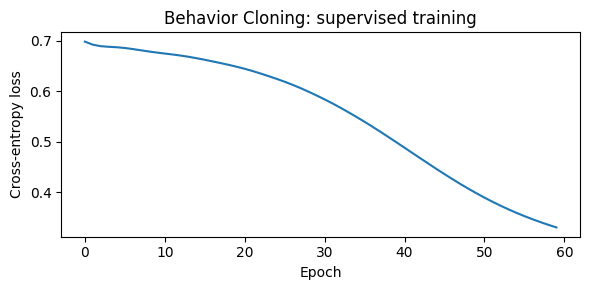

In [4]:
STATE_SCALE = torch.tensor([2.4, 3.0, 0.21, 3.0], dtype=torch.float32)

class ClonedPolicy(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 2)
        )

    def forward(self, states):
        return self.net(states / STATE_SCALE)

def train_bc(states, actions, epochs=60, learning_rate=3e-3):
    policy = ClonedPolicy()
    optimizer = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    X = torch.as_tensor(states, dtype=torch.float32)
    y = torch.as_tensor(actions, dtype=torch.long)
    losses = []
    for epoch in range(epochs):
        logits = policy(X)
        loss = nn.functional.cross_entropy(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))
    return policy, losses

bc_policy, bc_losses = train_bc(X_train, y_train, epochs=60)
with torch.inference_mode():
    logits = bc_policy(torch.tensor(X_test))
    holdout_accuracy = (logits.argmax(1).numpy() == y_test).mean()
print(f'Held-out expert action accuracy: {holdout_accuracy:.1%}')
plt.figure(figsize=(6, 3)); plt.plot(bc_losses); plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss'); plt.title('Behavior Cloning: supervised training'); plt.tight_layout(); plt.show()

**Important:** The action accuracy above is measured on **expert-generated** states. It does not tell us how well the cloned policy performs on states it causes itself to visit.

To test the actual task, we must **roll the policy out in the simulator** and measure episode return.

## Part 5 — Closed-loop performance: Random vs. Expert vs. Cloned policy

An action classifier can have reasonable accuracy and still be an unreliable controller. We measure the **number of steps before failure or the 500-step time limit**. This is equivalent to episode return for the default CartPole reward of +1 per step.

In [5]:
def cloned_action(policy, obs):
    policy.eval()
    with torch.inference_mode():
        x = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)
        return int(policy(x).argmax(dim=1).item())

def evaluate_controller(controller, n_episodes=12, first_seed=2000,
                        reset_bounds=None):
    env = make_env()
    returns = []
    for i in range(n_episodes):
        options = None if reset_bounds is None else {
            'low': -float(reset_bounds), 'high': float(reset_bounds)}
        obs, _ = env.reset(seed=first_seed + i, options=options)
        total = 0.
        while True:
            a = int(controller(obs))
            obs, reward, terminated, truncated, _ = env.step(a)
            total += float(reward)
            if terminated or truncated:
                break
        returns.append(total)
    env.close()
    return np.asarray(returns)

random_rng = np.random.default_rng(77)
controllers = {
    'Random': lambda obs: int(random_rng.integers(2)),
    'Scripted expert': expert_action,
    'Behavior cloning': lambda obs: cloned_action(bc_policy, obs),
}
for name, fn in controllers.items():
    scores = evaluate_controller(fn)
    print(f'{name:17s} average {scores.mean():6.1f}, '
          f'min {scores.min():5.0f}, max {scores.max():5.0f}')

Random            average   21.2, min    11, max    42
Scripted expert   average  500.0, min   500, max   500


Behavior cloning  average  367.8, min   154, max   500


## Part 6 — Distribution shift: is the learner robust?

The expert demonstrations began very close to upright (`±0.05` in each observation dimension). Now start from a **wider range of initial conditions** (`±0.15`). In Gymnasium, `reset(options={"low":..., "high":...})` changes the initial-state bounds.

This is a teaching stress test, not a general proof about covariate shift.

In [6]:
before = evaluate_controller(lambda o: cloned_action(bc_policy, o),
                             n_episodes=12, reset_bounds=0.15)
expert_shift = evaluate_controller(expert_action, n_episodes=12,
                                   reset_bounds=0.15)
print('BC under shifted starts:', round(before.mean(), 1),
      'steps; expert:', round(expert_shift.mean(), 1), 'steps')
print('BC shifted episode scores:', before.astype(int).tolist())

BC under shifted starts: 161.2 steps; expert: 443.4 steps
BC shifted episode scores: [116, 250, 153, 113, 116, 106, 184, 160, 132, 102, 157, 346]


### Why small errors compound

Behavior Cloning trains on states sampled from the expert distribution, $d^{\pi_E}(s)$. But the deployed policy generates states from **its own** distribution, $d^{\pi_{BC}}(s)$.

One wrong action → unfamiliar state → more wrong actions → task failure.

Think back to the Grand Prix: even if a steering model agrees with the expert on most *on-track* frames, can it recover once it drifts toward an unfamiliar edge of the track?

## Part 7 — DAgger: Dataset Aggregation (simplified teaching implementation)

1. Run the **learner** to collect the states that **it** visits.
2. Ask the expert to label those learner-visited states.
3. Add those newly labeled examples to the demonstration dataset.
4. Retrain the policy and repeat.

We use a fixed scripted expert that can label any simulated CartPole state. A real-world implementation might require costly human labels and safety review.

**Crucial:** DAgger requires interaction to visit learner-induced states and is **not** the fixed-dataset offline RL setting of Lecture 10B.

DAgger round 1: dataset 2345 examples; average shifted-start return 383.2


DAgger round 2: dataset 3845 examples; average shifted-start return 334.1


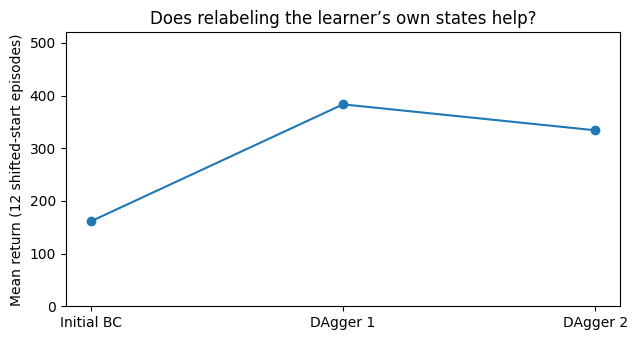

Expert shifted-start baseline: 443.4


In [7]:
def collect_dagger_states(policy, n_episodes=3, seed_start=3000):
    env = make_env()
    learner_states, teacher_labels = [], []
    for episode in range(n_episodes):
        obs, _ = env.reset(seed=seed_start + episode)
        while True:
            learner_states.append(obs.copy())
            teacher_labels.append(expert_action(obs))  # query expert
            action = cloned_action(policy, obs)          # execute learner
            obs, reward, terminated, truncated, _ = env.step(action)
            if terminated or truncated:
                break
    env.close()
    return np.asarray(learner_states, dtype=np.float32),            np.asarray(teacher_labels, dtype=np.int64)

aggregated_X, aggregated_y = X_train.copy(), y_train.copy()
dag_policy = bc_policy
dag_results = [evaluate_controller(lambda s: cloned_action(dag_policy, s),
                                   n_episodes=12, reset_bounds=0.15).mean()]
for iteration in range(2):
    new_states, new_labels = collect_dagger_states(
        dag_policy, n_episodes=3, seed_start=3000 + iteration * 20)
    aggregated_X = np.concatenate([aggregated_X, new_states])
    aggregated_y = np.concatenate([aggregated_y, new_labels])
    torch.manual_seed(100 + iteration)
    dag_policy, _ = train_bc(aggregated_X, aggregated_y, epochs=80)
    score = evaluate_controller(lambda s: cloned_action(dag_policy, s),
                                n_episodes=12, reset_bounds=0.15).mean()
    dag_results.append(score)
    print(f'DAgger round {iteration+1}: dataset {len(aggregated_X)} '
          f'examples; average shifted-start return {score:.1f}')

plt.figure(figsize=(6.5, 3.5))
plt.plot(range(len(dag_results)), dag_results, marker='o')
plt.xticks(range(len(dag_results)), ['Initial BC', 'DAgger 1', 'DAgger 2'])
plt.ylim(0, 520); plt.ylabel('Mean return (12 shifted-start episodes)')
plt.title('Does relabeling the learner’s own states help?')
plt.tight_layout(); plt.show()
print('Expert shifted-start baseline:', expert_shift.mean().round(1))

### Interpretation and limitations

- DAgger frequently helps because the student learns the expert's preferred decisions **in the states caused by its own mistakes**.
- Improvements are **not guaranteed**: the expert may be imperfect, learner rollouts might not visit the right states, and the neural network may need different tuning.
- This is a **simplified DAgger classroom loop** with the learner always acting and the expert only labeling; original DAgger includes policies mixed with the expert for early data collection and theoretical guarantees under assumptions.
- To fairly compare algorithms in a report, evaluate several random seeds and report variability, not just one plotted mean.

## Part 8 — Two questions to connect with Week 10B (Offline RL)

**Q1.** Where was the reward function used in the Behavior Cloning loss?  
*Answer:* Nowhere. Only expert state-action pairs trained the classifier; rewards were used solely for evaluating policy performance.

**Q2.** Suppose you're prohibited from running your learner at all and can access only a fixed database \((s,a,r,s',done)\). Could you still execute DAgger?  
*Answer:* No. DAgger needs interaction to get new learner-visited states and their expert labels. A fixed transition dataset motivates **offline RL**.

### Student challenges (choose one)

1. Train BC with 1, 2, 4, and 8 expert episodes. Compare **expert-action classification accuracy** with **actual episode return**.
2. Increase the reset range from `0.05` to `0.15`, then `0.18`. Quantify robustness; if the environment terminates quickly, explain why.
3. Introduce noisy expert labels (e.g. flip 5% of actions). Investigate policy performance.
4. For graduate students: replace the scripted expert with a saved PPO policy from an earlier lecture, and compare the two teachers.
5. Explain why DAgger is different from offline RL.

### References
- Ross, Gordon & Bagnell (2011), *A Reduction of Imitation Learning and Structured Prediction to No-Regret Online Learning*: https://proceedings.mlr.press/v15/ross11a.html
- Berkeley CS285 Imitation Learning exercise: https://rail.eecs.berkeley.edu/deeprlcourse-fa21/static/homeworks/hw1.pdf
- Gymnasium CartPole-v1 and reset/step API: https://gymnasium.farama.org/
